In [1]:
suppressPackageStartupMessages({
library(Seurat)
library(SeuratWrappers)
library(DropletUtils)
library(tidyverse)
library(scDblFinder)
library(dittoSeq
library(patchwork)
})

theme_set(theme_classic(16))

# Set working directory for saving and accessing files
setwd("/data/pam/team333/skb/scratch/SNIP_paper/04_analysis/")
set.seed(123)

In [4]:
samples <- c("HconF_1", "HconM_1", "HconL3_1", "TmurF_1", "TmurM_1",
             "HconF_2", "HconM_2", "HconL3_2", "TmurF_2", "TmurM_2")

In [5]:
# Create a lookup table for uploading split-pipe output files
basedir <- "/data/pam/team333/skb/scratch/SNIP_paper/02_data/split_pipe_out"

sample_info <- data.frame(
  species = c(rep("hcontortus", 3), rep("tmuris", 2),
              rep("hcontortus", 3), rep("tmuris", 2)),
  run     = c(rep("48163_1_1", 5), rep("48240_1_combined", 5)),
  stage   = rep(c("adult_female", "adult_male", "L3", "adult_female", "adult_male"), 2),
  row.names = samples
)

sample_info

,species,run,stage
,<chr>,<chr>,<chr>
HconF_1,hcontortus,48163_1_1,adult_female
HconM_1,hcontortus,48163_1_1,adult_male
HconL3_1,hcontortus,48163_1_1,L3
TmurF_1,tmuris,48163_1_1,adult_female
TmurM_1,tmuris,48163_1_1,adult_male
HconF_2,hcontortus,48240_1_combined,adult_female
HconM_2,hcontortus,48240_1_combined,adult_male
HconL3_2,hcontortus,48240_1_combined,L3
TmurF_2,tmuris,48240_1_combined,adult_female


In [6]:
# Double-check path against lookup table
paths <- sapply(samples, function(i) {
  info <- sample_info[i, ]
  file.path(basedir,
            paste0(info$species, "_", info$run),
            paste0(info$species, "_", info$stage),
            "DGE_unfiltered")
})

writeLines(paste0(samples, ": ", paths))

HconF_1: /data/pam/team333/skb/scratch/SNIP_paper/02_data/split_pipe_out/hcontortus_48163_1_1/hcontortus_adult_female/DGE_unfiltered
HconM_1: /data/pam/team333/skb/scratch/SNIP_paper/02_data/split_pipe_out/hcontortus_48163_1_1/hcontortus_adult_male/DGE_unfiltered
HconL3_1: /data/pam/team333/skb/scratch/SNIP_paper/02_data/split_pipe_out/hcontortus_48163_1_1/hcontortus_L3/DGE_unfiltered
TmurF_1: /data/pam/team333/skb/scratch/SNIP_paper/02_data/split_pipe_out/tmuris_48163_1_1/tmuris_adult_female/DGE_unfiltered
TmurM_1: /data/pam/team333/skb/scratch/SNIP_paper/02_data/split_pipe_out/tmuris_48163_1_1/tmuris_adult_male/DGE_unfiltered
HconF_2: /data/pam/team333/skb/scratch/SNIP_paper/02_data/split_pipe_out/hcontortus_48240_1_combined/hcontortus_adult_female/DGE_unfiltered
HconM_2: /data/pam/team333/skb/scratch/SNIP_paper/02_data/split_pipe_out/hcontortus_48240_1_combined/hcontortus_adult_male/DGE_unfiltered
HconL3_2: /data/pam/team333/skb/scratch/SNIP_paper/02_data/split_pipe_out/hcontortus_4

In [7]:
# Read in Parse split-pipe output data 
data_list <- setNames(lapply(samples, function(i) {
  info <- sample_info[i, ]
  ReadParseBio(data.dir = file.path(
    basedir,
    paste0(info$species, "_", info$run),
    paste0(info$species, "_", info$stage),
    "DGE_unfiltered"
  ))
}), samples)

In [8]:
# Check the genes x cells matrix from ReadParseBio is loaded correctly per sample
writeLines(paste0(samples, ": ",
                  sapply(data_list, function(m) class(m)[1]), ", ",
                  sapply(data_list, nrow), " genes x ",
                  sapply(data_list, ncol), " cells"))

HconF_1: dgCMatrix, 19778 genes x 2618 cells
HconM_1: dgCMatrix, 19778 genes x 1708 cells
HconL3_1: dgCMatrix, 19778 genes x 7332 cells
TmurF_1: dgCMatrix, 15755 genes x 8141 cells
TmurM_1: dgCMatrix, 15755 genes x 4027 cells
HconF_2: dgCMatrix, 19778 genes x 35526 cells
HconM_2: dgCMatrix, 19778 genes x 32886 cells
HconL3_2: dgCMatrix, 19778 genes x 17552 cells
TmurF_2: dgCMatrix, 15755 genes x 4173 cells
TmurM_2: dgCMatrix, 15755 genes x 3627 cells


In [9]:
# Check the count matrices contain actual counts
writeLines(paste0(samples, ": ",
                  sapply(data_list, function(m) sum(m)), " total counts, ",
                  sapply(data_list, function(m) length(m@x)), " non-zero entries"))

HconF_1: 623516 total counts, 339222 non-zero entries
HconM_1: 223533 total counts, 139662 non-zero entries
HconL3_1: 1410971 total counts, 661266 non-zero entries
TmurF_1: 1762249 total counts, 709132 non-zero entries
TmurM_1: 1059316 total counts, 431941 non-zero entries
HconF_2: 29294244 total counts, 11705669 non-zero entries
HconM_2: 6247012 total counts, 2735508 non-zero entries
HconL3_2: 6876730 total counts, 4406518 non-zero entries
TmurF_2: 555015 total counts, 279363 non-zero entries
TmurM_2: 173155 total counts, 119801 non-zero entries


In [10]:
# Read Parse split-pipe outout cell meta data csv files
meta_list <- setNames(lapply(samples, function(i) {
  read.csv(file.path(paths[[i]], "cell_metadata.csv"), row.names = 1)
    }
), samples)

for (i in samples) assign(paste0(i, "_meta"), meta_list[[i]])

In [33]:
# Check the meta data files were read correctly by counting rows and columns per sample
writeLines(paste0(samples, ": ",
                  sapply(meta_list, nrow), " nuclei x ",
                  sapply(meta_list, ncol), " columns"))

HconF_1: 2618 nuclei x 8 columns
HconM_1: 1708 nuclei x 8 columns
HconL3_1: 7332 nuclei x 8 columns
TmurF_1: 8141 nuclei x 8 columns
TmurM_1: 4027 nuclei x 8 columns
HconF_2: 35526 nuclei x 8 columns
HconM_2: 32886 nuclei x 8 columns
HconL3_2: 17552 nuclei x 8 columns
TmurF_2: 4173 nuclei x 8 columns
TmurM_2: 3627 nuclei x 8 columns


In [34]:
# Check the meta data matches the count matrices
writeLines(paste0(samples, ": ",
                  sapply(samples, function(i)
                    sum(rownames(meta_list[[i]]) %in% colnames(data_list[[i]])) ),
                  " of ", sapply(meta_list, nrow), " metadata cells found in counts"))

HconF_1: 2618 of 2618 metadata cells found in counts
HconM_1: 1708 of 1708 metadata cells found in counts
HconL3_1: 7332 of 7332 metadata cells found in counts
TmurF_1: 8141 of 8141 metadata cells found in counts
TmurM_1: 4027 of 4027 metadata cells found in counts
HconF_2: 35526 of 35526 metadata cells found in counts
HconM_2: 32886 of 32886 metadata cells found in counts
HconL3_2: 17552 of 17552 metadata cells found in counts
TmurF_2: 4173 of 4173 metadata cells found in counts
TmurM_2: 3627 of 3627 metadata cells found in counts


In [ ]:
# Create Seurat objects from data loaded above
seurat_objs <- Map(
  function(counts, meta) CreateSeuratObject(counts, names.field = 0, meta.data = meta),
  data_list[samples], meta_list[samples]
)

# Append names with _obj suffix
names(seurat_objs) <- paste0(samples, "_obj")

In [37]:
seurat_objs

$HconF_1_obj
An object of class Seurat 
19778 features across 2618 samples within 1 assay 
Active assay: RNA (19778 features, 0 variable features)
 1 layer present: counts

$HconM_1_obj
An object of class Seurat 
19778 features across 1708 samples within 1 assay 
Active assay: RNA (19778 features, 0 variable features)
 1 layer present: counts

$HconL3_1_obj
An object of class Seurat 
19778 features across 7332 samples within 1 assay 
Active assay: RNA (19778 features, 0 variable features)
 1 layer present: counts

$TmurF_1_obj
An object of class Seurat 
15755 features across 8141 samples within 1 assay 
Active assay: RNA (15755 features, 0 variable features)
 1 layer present: counts

$TmurM_1_obj
An object of class Seurat 
15755 features across 4027 samples within 1 assay 
Active assay: RNA (15755 features, 0 variable features)
 1 layer present: counts

$HconF_2_obj
An object of class Seurat 
19778 features across 35526 samples within 1 assay 
Active assay: RNA (19778 features, 0 varia

In [87]:
# Save Seurat objects
for (i in samples) {
  saveRDS(seurat_objs[[paste0(i,"_obj")]],
          file = file.path("seurat_obj", paste0(i, "_obj.rds")))
}

# Check files were written
writeLines(list.files("seurat_obj"))

In [12]:
# Set count and barcode factors and put into data frame
params <- data.frame(
  cutoff = c(194.80, 209.05, 184.94, 127.79, 186.75,
             887.77, 1102.74, 587.79, 44.86, 97.00),
  row.names = samples
)

raw_counts <- setNames(lapply(samples, function(i) {
  GetAssayData(seurat_objs[[paste0(i, "_obj")]], layer = "counts")
}), samples)

barcode_ranks <- lapply(raw_counts, barcodeRanks)

barcode_data <- lapply(barcode_ranks, as.data.frame)

barcode_points <- setNames(lapply(samples, function(i) {
  data.frame(type = "cutoff", value = params[i, "cutoff"])
}), samples)

# Check values are matched with correct sample
writeLines(paste0(samples, ": ", sapply(samples, function(i) params[i, "cutoff"])))

HconF_1: 194.8
HconM_1: 209.05
HconL3_1: 184.94
TmurF_1: 127.79
TmurM_1: 186.75
HconF_2: 887.77
HconM_2: 1102.74
HconL3_2: 587.79
TmurF_2: 44.86
TmurM_2: 97


In [ ]:
plots <- setNames(lapply(samples, function(i) {
  cutoff <- params[i, "cutoff"]

ggplot(data = barcode_data[[i]], aes(x = rank, y = total)) +
    geom_point() +
    geom_hline(data = barcode_points[[i]],
               aes(yintercept = value, colour = type), linetype = 2) +
    annotate("text",
             x = Inf, y = cutoff,
             label = paste0("Cut-off: \n", cutoff),
             hjust = 1, vjust = -0.2,
             colour = "red", size = 5) +
    scale_colour_manual(values = c(cutoff = "red")) +
    scale_x_log10(breaks = trans_breaks("log10", function(x) 10^x),
                  labels = trans_format("log10", math_format(10^.x))) +
    scale_y_log10(breaks = trans_breaks("log10", function(x) 10^x),
                  labels = trans_format("log10", math_format(10^.x))) +
    labs(title = i,
         x = "Barcode Rank (log scale)",
         y = "Transcript Count (log scale)") +
         guides(colour = "none")
}), samples)

options(repr.plot.width=5, repr.plot.height=5)

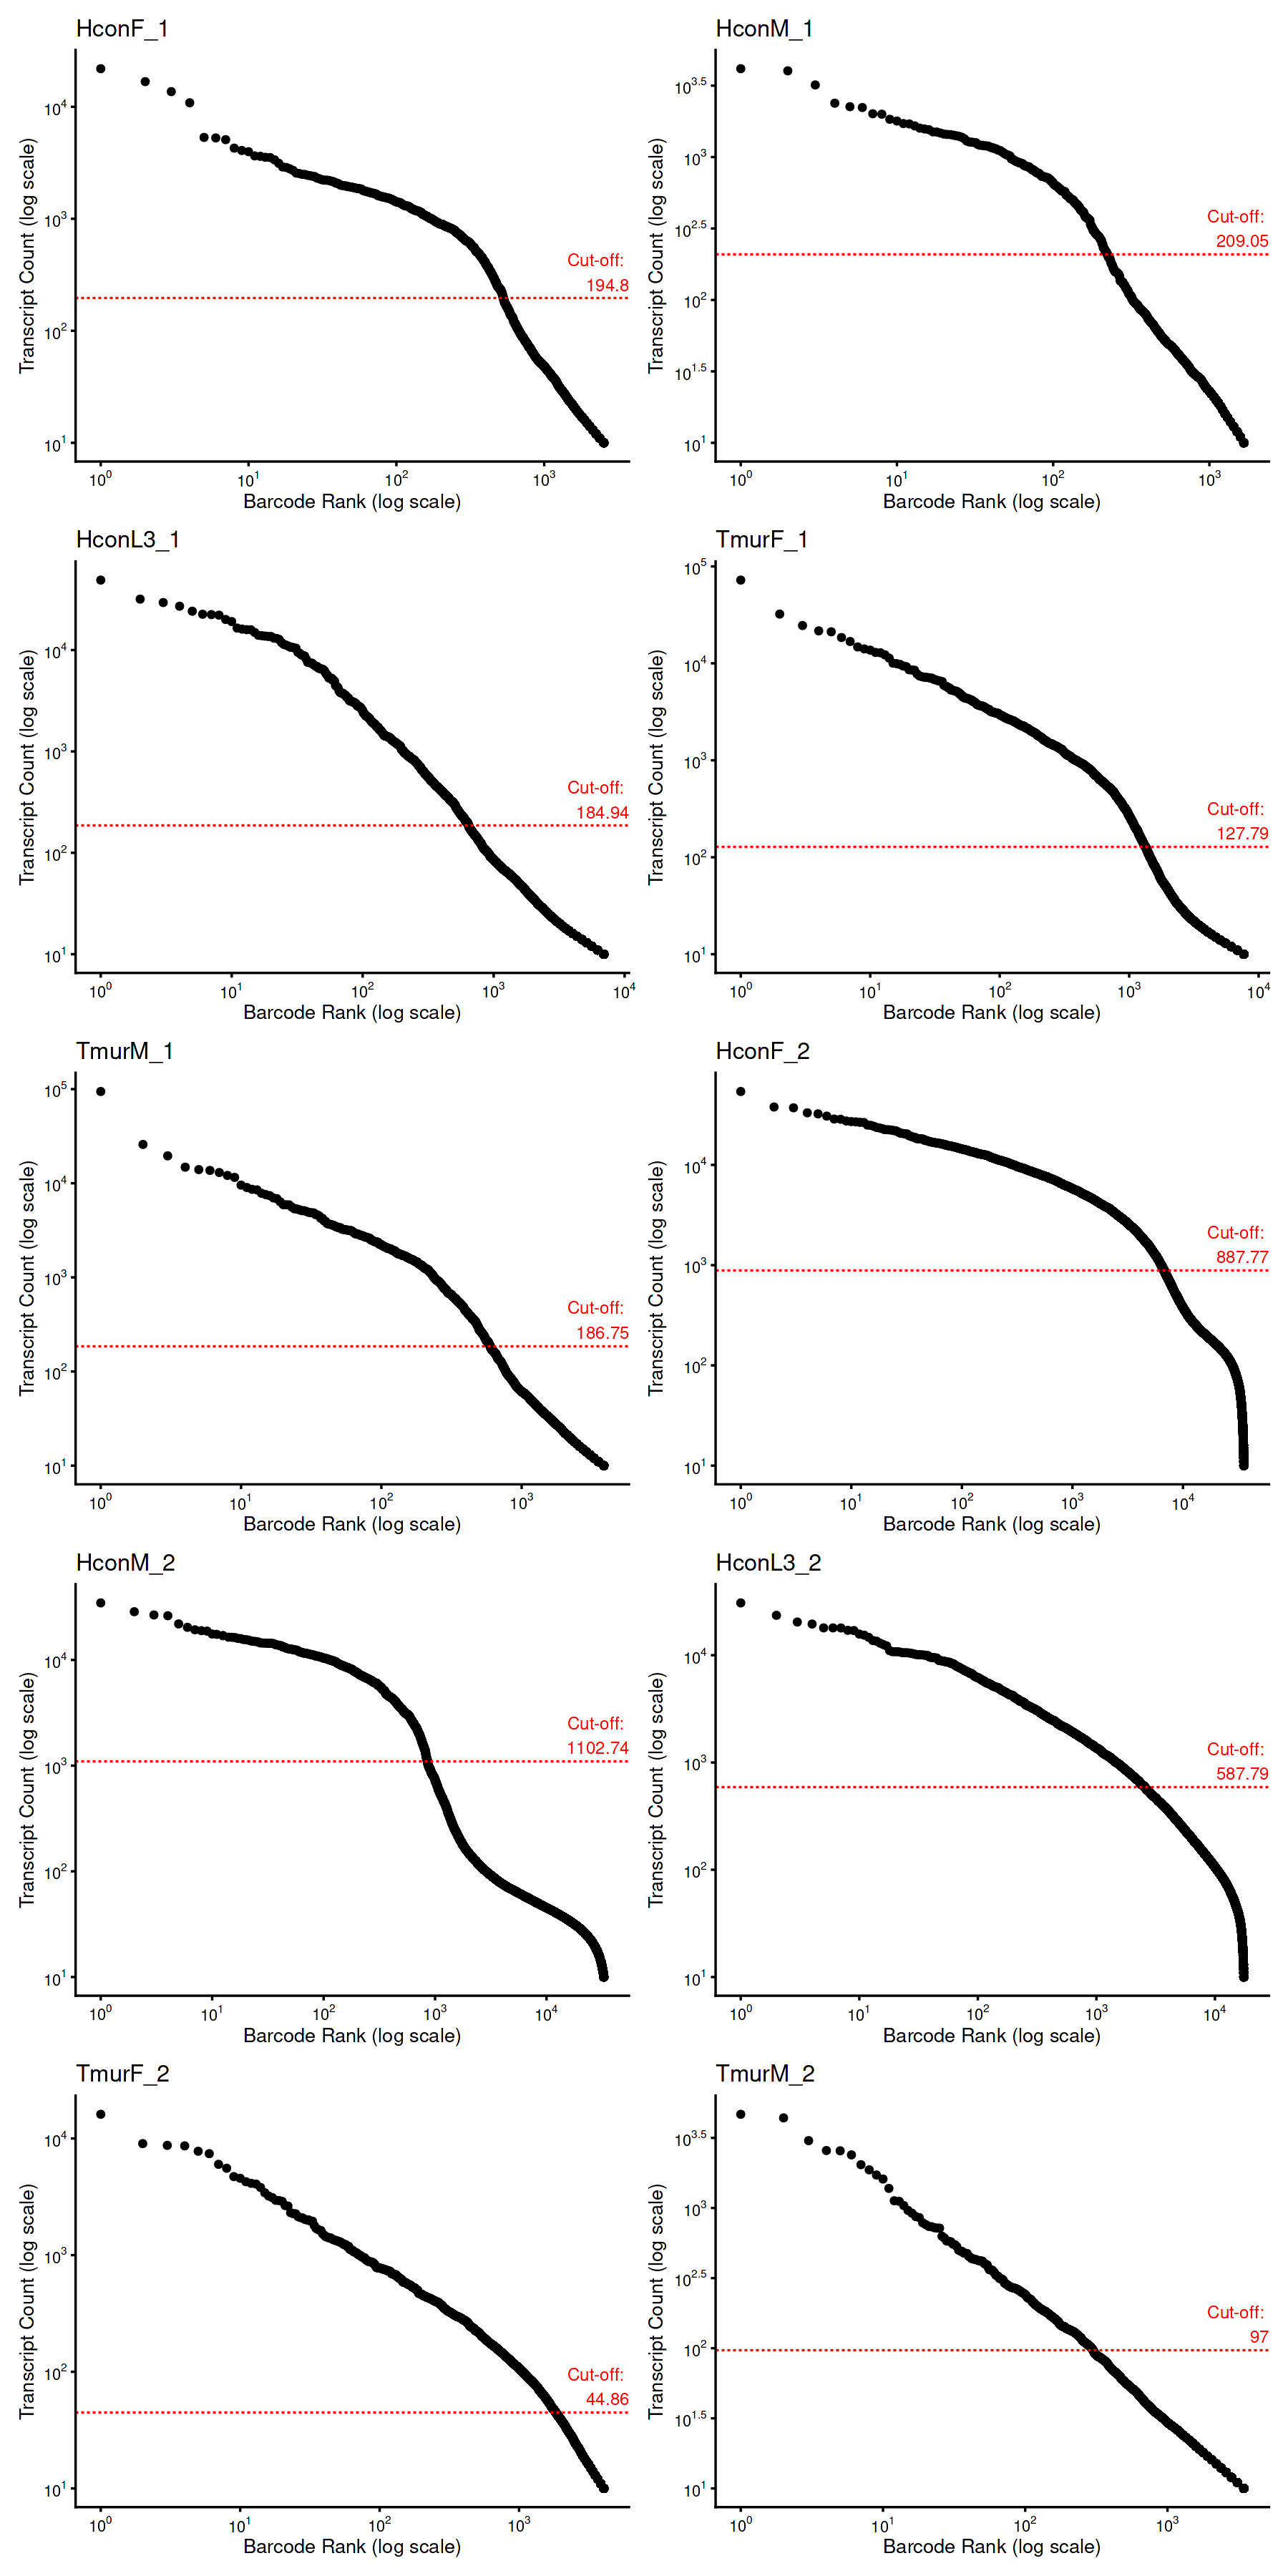

In [19]:
options(repr.plot.width=15, repr.plot.height=30)
waterfalls <- wrap_plots(plots, nrow = 5, ncol = 2)
waterfalls

ggsave("waterfall_plots.png", plot = waterfalls, width = 30, height = 50, dpi = 600, units = "cm")

In [20]:
# Subset data on nCount_RNA > cut-off value for each sample
seurat_objs_filt <- setNames(lapply(samples, function(i) {
  obj    <- seurat_objs[[paste0(i, "_obj")]]
  cutoff <- params[i, "cutoff"]

  keep <- colnames(obj)[obj$nCount_RNA > cutoff]
  subset(obj, cells = keep)
}), paste0(samples, "_obj"))

In [108]:
# Save the filtered object and check files were written
for (i in samples) {
  saveRDS(seurat_objs_filt[[paste0(i, "_obj")]],
          file = file.path("seurat_obj", paste0(i, "_obj_filt.rds")))
}

# Check files were written
writeLines(list.files("seurat_obj", pattern = "_filt.rds"))

HconF_1_obj_filt.rds
HconF_2_obj_filt.rds
HconL3_1_obj_filt.rds
HconL3_2_obj_filt.rds
HconM_1_obj_filt.rds
HconM_2_obj_filt.rds
TmurF_1_obj_filt.rds
TmurF_2_obj_filt.rds
TmurM_1_obj_filt.rds
TmurM_2_obj_filt.rds


In [83]:
# Quick count of number of nuclei filtered
before  <- sapply(samples, function(i) ncol(seurat_objs[[paste0(i, "_obj")]]))
after   <- sapply(samples, function(i) ncol(seurat_objs_filt[[paste0(i, "_obj")]]))
removed <- before - after

writeLines(paste0(samples, ": ", removed, " removed (",
                  before, " -> ", after, ", ",
                  round(100 * removed / before, 1), "%)"))

HconF_1: 2089 removed (2618 -> 529, 79.8%)
HconM_1: 1487 removed (1708 -> 221, 87.1%)
HconL3_1: 6686 removed (7332 -> 646, 91.2%)
TmurF_1: 6800 removed (8141 -> 1341, 83.5%)
TmurM_1: 3432 removed (4027 -> 595, 85.2%)
HconF_2: 28799 removed (35526 -> 6727, 81.1%)
HconM_2: 32033 removed (32886 -> 853, 97.4%)
HconL3_2: 14988 removed (17552 -> 2564, 85.4%)
TmurF_2: 2331 removed (4173 -> 1842, 55.9%)
TmurM_2: 3329 removed (3627 -> 298, 91.8%)


In [ ]:
# Transform the Seurat objects into SingleCellExperiments (warning message means nothing because the normalized data layer and scale.data layer in the seurat objects are empty as we have not run those yet)
library(SingleCellExperiment)
sce_list <- setNames(lapply(samples, function(i) {
  as.SingleCellExperiment(seurat_objs_filt[[paste0(i, "_obj")]])
}), paste0(samples, "_sce"))

In [ ]:
# Run scDblFinder
sce_list <- lapply(sce_list, function(sce) {
  scDblFinder(sce, samples = "orig.ident")
})

In [23]:
# Quick count of singlets and doublets for each sample
dbl_table <- t(sapply(sce_list, function(s) {
  table(factor(s$scDblFinder.class, levels = c("singlet", "doublet")))
}))

dbl_table

,singlet,doublet
HconF_1_sce,509,20
HconM_1_sce,214,7
HconL3_1_sce,610,36
TmurF_1_sce,1282,59
TmurM_1_sce,550,45
HconF_2_sce,6005,722
HconM_2_sce,816,37
HconL3_2_sce,2421,143
TmurF_2_sce,1755,87
TmurM_2_sce,288,10


In [24]:
# scDblFinder will output 5 new columns to our sce metadata: sample, class (singlet or doublet), score, weighted score, and cxds score. Because we started with a Seurat object, we need to add the doublet labels to the original Seurat object.
seurat_objs_filt <- setNames(lapply(samples, function(i) {
  sce <- sce_list[[paste0(i, "_sce")]]
  obj <- seurat_objs_filt[[paste0(i, "_obj")]]

  dbl_meta <- as.data.frame(colData(sce)) %>%
    dplyr::select(starts_with("scDblFinder"))   # rownames are the cell barcodes

  AddMetaData(obj, metadata = dbl_meta %>% dplyr::select("scDblFinder.class"))
}), paste0(samples, "_obj"))

In [ ]:
# Check how doublets singlets differ in QC measures per sample (again, ignore warning message about data layer missing)
vln_plots <- setNames(lapply(samples, function(i) {
    obj <- seurat_objs_filt[[paste0(i, "_obj")]]
    obj$sample_id <- i #Set x-axis label to sample id name (e.g. HconF_1)

  VlnPlot(obj,
          group.by = "sample_id", split.by = "scDblFinder.class",
          features = c("nFeature_RNA", "nCount_RNA"),
          ncol = 3, pt.size = 0.1, alpha = 0.05, log = TRUE) +
    plot_layout(guides = "collect") +
    plot_annotation(title = i) &
    theme(legend.position = "right")
}), samples)

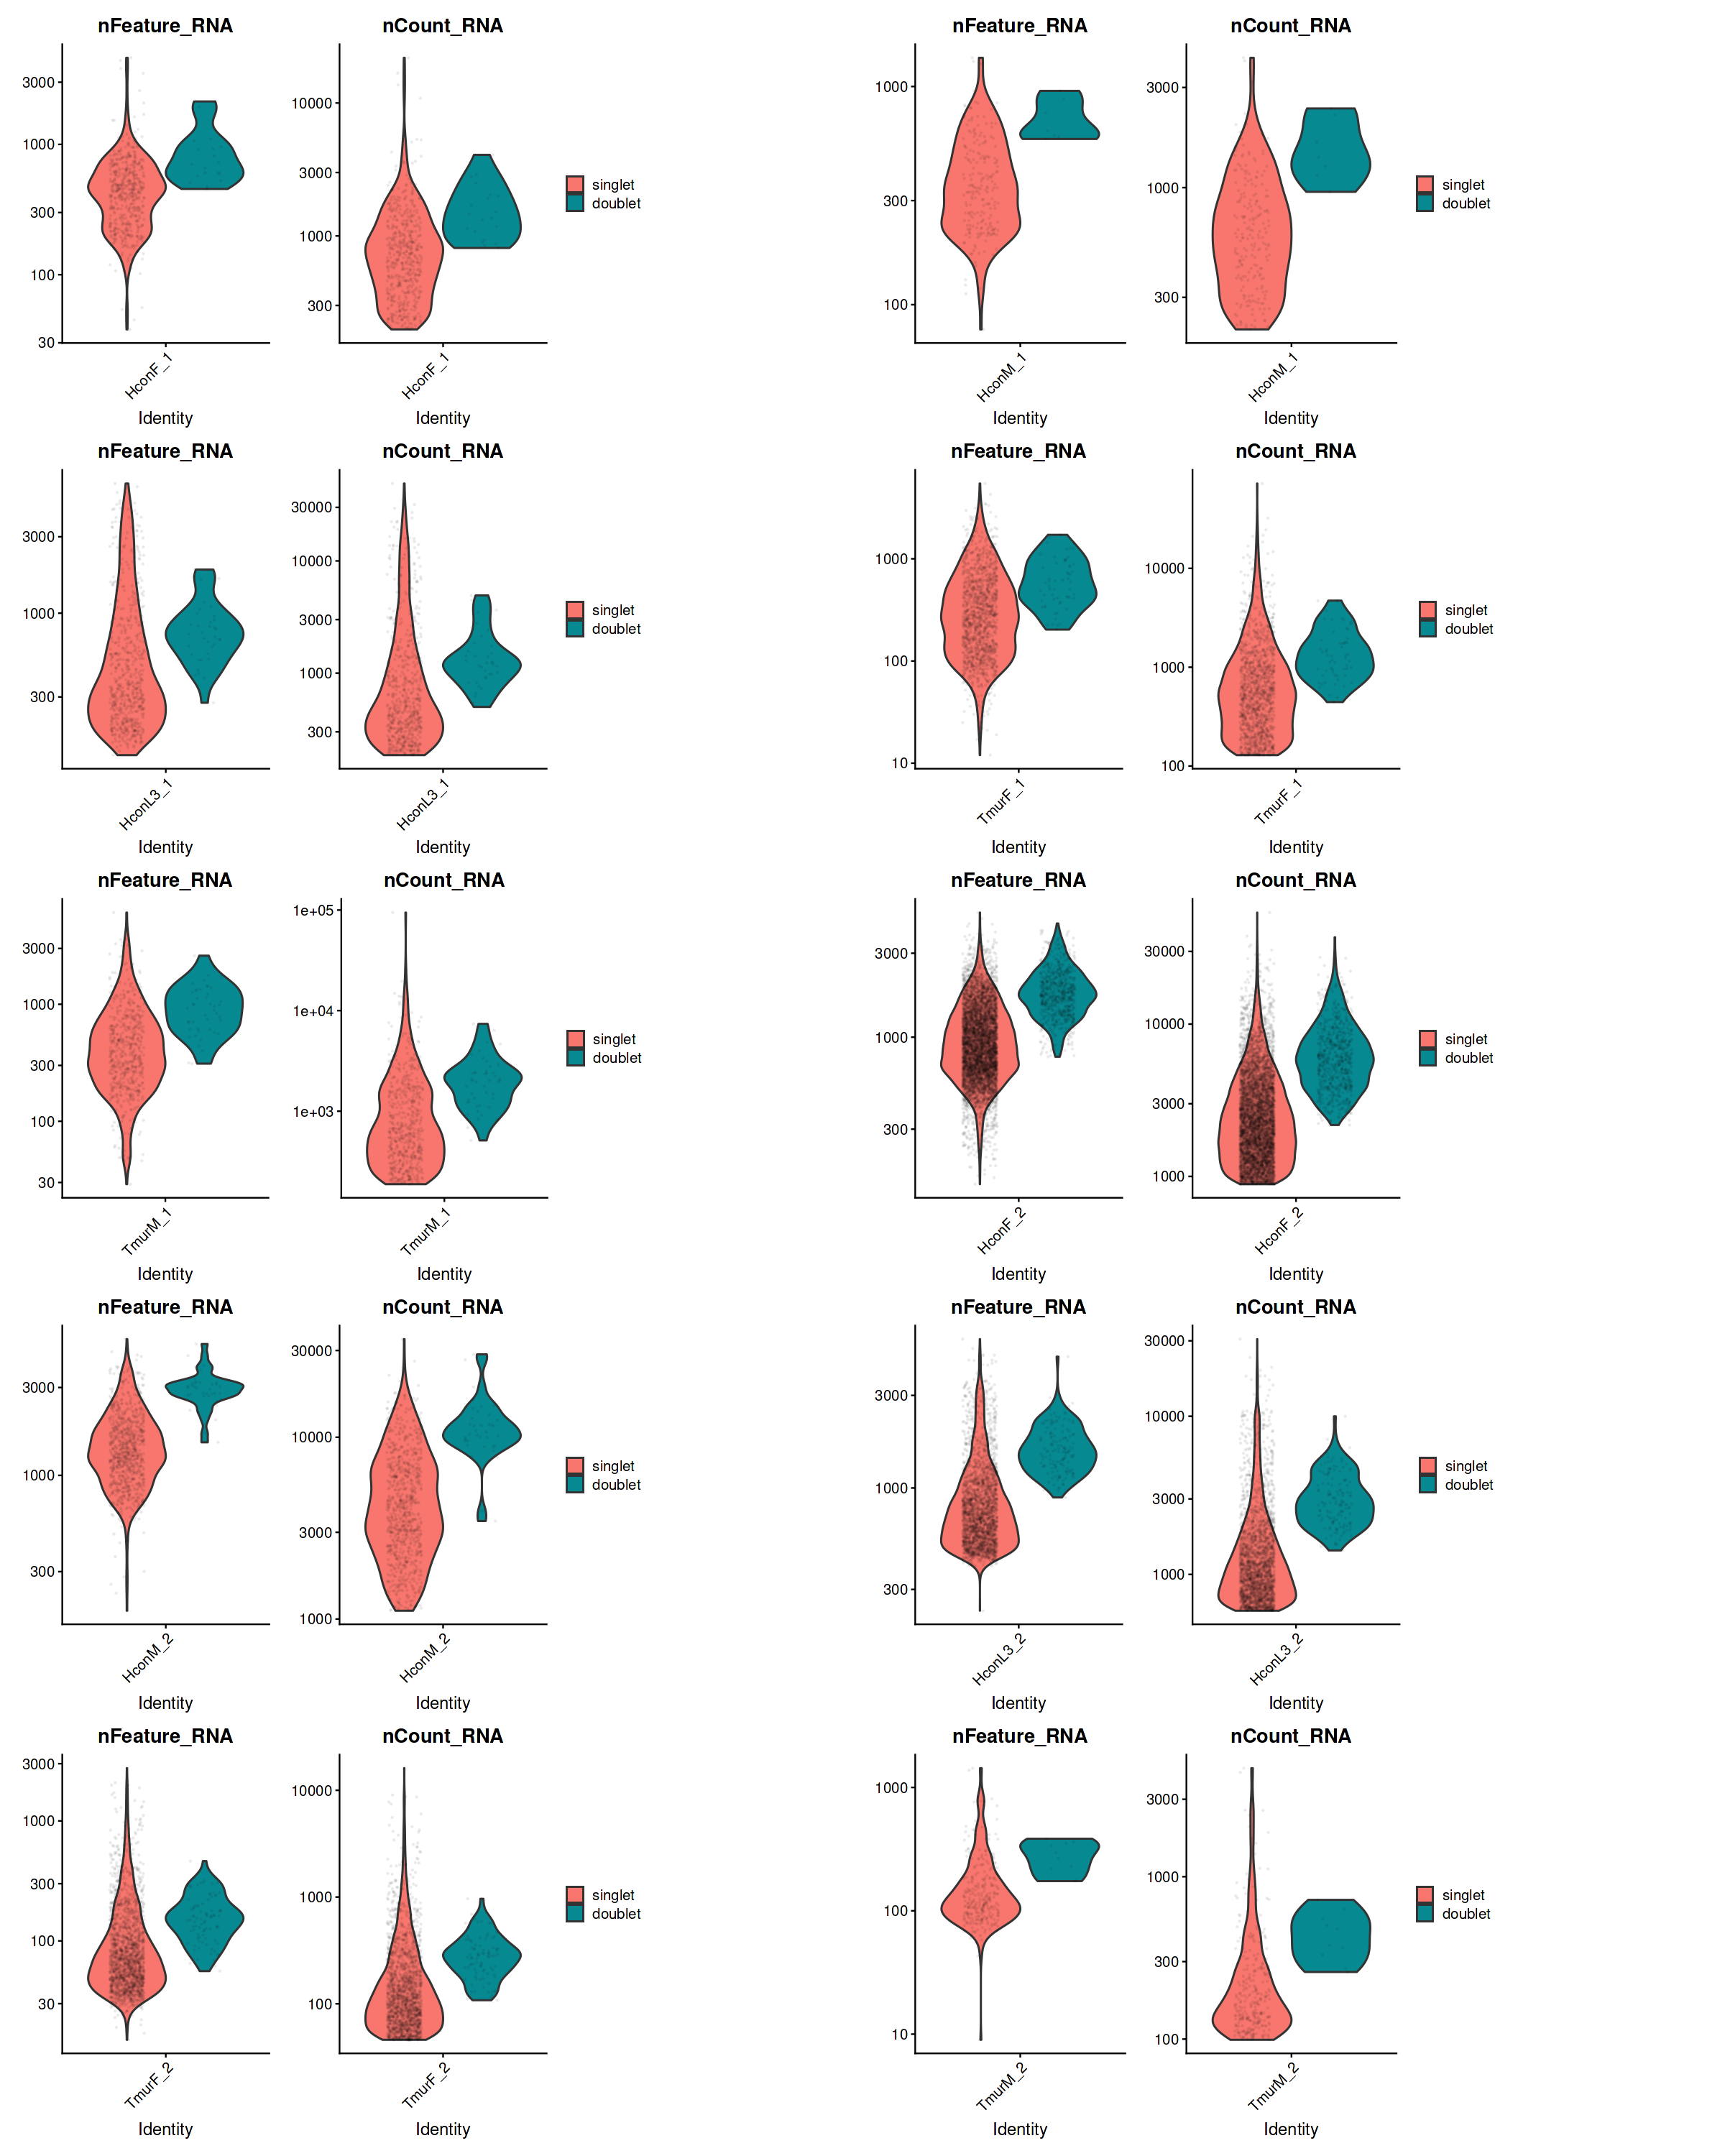

In [41]:
options(repr.plot.width=20, repr.plot.height=25)

dbls <- wrap_plots(vln_plots, nrow = 5, ncol = 2) +
            plot_layout(guides = "collect") &
            theme(legend.position = "right")
dbls

ggsave("dblQC_plots.png", plot = dbls, width = 30, height = 50, dpi = 600, units = "cm")

In [100]:
# Subset seurat objects to keep only singlets 
seurat_objs_singlets <- setNames(lapply(samples, function(i) {
  obj  <- seurat_objs_filt[[paste0(i, "_obj")]]
  keep <- colnames(obj)[obj$scDblFinder.class == "singlet"]
  subset(obj, cells = keep)
}), paste0(samples, "_obj"))

In [101]:
# Quick count of number of nuclei filtered
before  <- sapply(samples, function(i) ncol(seurat_objs_filt[[paste0(i, "_obj")]]))
after   <- sapply(samples, function(i) ncol(seurat_objs_singlets[[paste0(i, "_obj")]]))
removed <- before - after

writeLines(paste0(samples, ": ", removed, " doublets removed (",
                  before, " -> ", after, ", ",
                  round(100 * removed / before, 1), "%)"))

HconF_1: 20 doublets removed (529 -> 509, 3.8%)
HconM_1: 7 doublets removed (221 -> 214, 3.2%)
HconL3_1: 36 doublets removed (646 -> 610, 5.6%)
TmurF_1: 59 doublets removed (1341 -> 1282, 4.4%)
TmurM_1: 45 doublets removed (595 -> 550, 7.6%)
HconF_2: 722 doublets removed (6727 -> 6005, 10.7%)
HconM_2: 37 doublets removed (853 -> 816, 4.3%)
HconL3_2: 143 doublets removed (2564 -> 2421, 5.6%)
TmurF_2: 87 doublets removed (1842 -> 1755, 4.7%)
TmurM_2: 10 doublets removed (298 -> 288, 3.4%)


In [109]:
# Save Seurat objects
for (i in samples) {
  saveRDS(seurat_objs_singlets[[paste0(i, "_obj")]],
          file = file.path("seurat_obj", paste0(i, "_obj_singlets.rds")))
}

# Check files were written
writeLines(list.files("seurat_obj", pattern = "_singlets.rds"))

HconF_1_obj_singlets.rds
HconF_2_obj_singlets.rds
HconL3_1_obj_singlets.rds
HconL3_2_obj_singlets.rds
HconM_1_obj_singlets.rds
HconM_2_obj_singlets.rds
TmurF_1_obj_singlets.rds
TmurF_2_obj_singlets.rds
TmurM_1_obj_singlets.rds
TmurM_2_obj_singlets.rds


In [166]:
# Group samples by species to prepare for merging into one Seurat object. Use species label from above. 
species_groups <- list(
  Hcon = samples[sample_info[samples, "species"] == "hcontortus"],
  Tmur = samples[sample_info[samples, "species"] == "tmuris"]
)

species_groups

$Hcon
[1] "HconF_1"  "HconM_1"  "HconL3_1" "HconF_2"  "HconM_2"  "HconL3_2"

$Tmur
[1] "TmurF_1" "TmurM_1" "TmurF_2" "TmurM_2"

In [169]:
# Merge species-specific Seurat objects
merged_objs <- lapply(species_groups, function(species_sample) {
  objs <- seurat_objs_singlets[paste0(species_sample, "_obj")]

  m <- merge(objs[[1]], y = objs[-1], add.cell.ids = species_sample)
  m$sample <- rep(species_sample, sapply(objs, ncol))   # adds a prefix of sample name ("species_sample") to each barcode
  m
})

In [170]:
table(merged_objs[["Hcon"]]$sample)
table(merged_objs[["Tmur"]]$sample)


 HconF_1  HconF_2 HconL3_1 HconL3_2  HconM_1  HconM_2 
     509     6005      610     2421      214      816 


TmurF_1 TmurF_2 TmurM_1 TmurM_2 
   1282    1755     550     288 

In [65]:
# Create separate variables for each merged data set to use going forward
Hcon_merged_obj <- merged_objs$Hcon
Tmur_merged_obj <- merged_objs$Tmur

In [ ]:
# Log normalize, scale, and top 2000 variable features (highly variable genes; HVGs)
Hcon_merged_obj <- NormalizeData(Hcon_merged_obj, normalization.method = "LogNormalize", scale.factor = 10000) %>% 
  FindVariableFeatures(selection.method = "vst", nfeatures = 2000) %>% 
  ScaleData()
Hcon_top2000 <- head(VariableFeatures(Hcon_merged_obj), 2000)
Hcon_merged_2kHVG <- Hcon_merged_obj[Hcon_top2000, ]

Tmur_merged_obj <- NormalizeData(Tmur_merged_obj, normalization.method = "LogNormalize", scale.factor = 10000) %>% 
  FindVariableFeatures(selection.method = "vst", nfeatures = 2000) %>% 
  ScaleData()
Tmur_top2000 <- head(VariableFeatures(Tmur_merged_obj), 2000)
Tmur_merged_2kHVG <- Tmur_merged_obj[Tmur_top2000, ]

In [ ]:
# Compute 50 PCs for each merged object
Hcon_merged_2kHVG <- RunPCA(Hcon_merged_2kHVG, npcs = 50)
Tmur_merged_2kHVG <- RunPCA(Tmur_merged_2kHVG, npcs = 50)

In [78]:
# Save merged Seurat objects
saveRDS(Hcon_merged_2kHVG, file = "seurat_obj/Hcon_merged_2kHVG.rds")
saveRDS(Tmur_merged_2kHVG, file = "seurat_obj/Tmur_merged_2kHVG.rds")

In [82]:
writeLines(list.files("seurat_obj", pattern = "_merged_2kHVG.rds"))

Hcon_merged_2kHVG.rds
Tmur_merged_2kHVG.rds


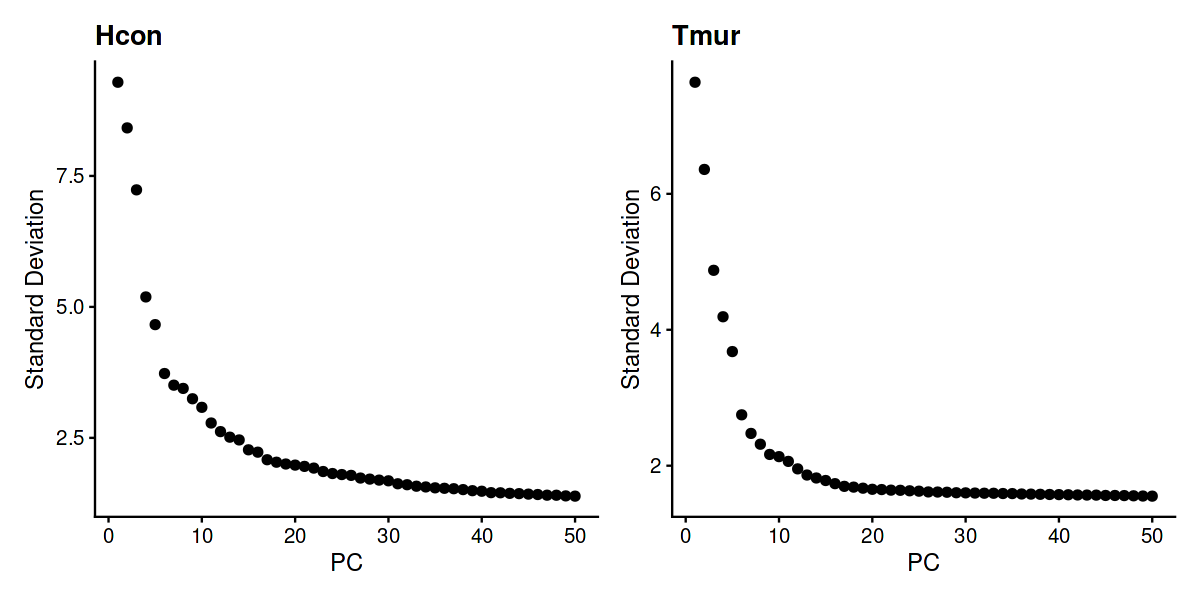

In [79]:
# Plot Elbow plot to see how much variance each PC explains 
options(repr.plot.width = 10, repr.plot.height = 5)

p1 <- ElbowPlot(Hcon_merged_2kHVG, ndims = 50) + ggtitle("Hcon")
p2 <- ElbowPlot(Tmur_merged_2kHVG, ndims = 50) + ggtitle("Tmur")

p1 + p2 + plot_layout(nrow = 1)

ggsave("elbow_plots.png", width = 20, height = 10, dpi = 600, units = "cm")

In [5]:
Hcon_merged_2kHVG <- readRDS("seurat_obj/Hcon_merged_2kHVG.rds")
Tmur_merged_2kHVG <- readRDS("seurat_obj/Tmur_merged_2kHVG.rds")

In [11]:
# The JackStrawPlot provides a visualisation for comparing the distribution of p-values for each PC with a uniform distribution (dashed line). Significant PCs will show a strong enrichment of features with low-p-values (above dashed)
hcon_js <- JackStraw(Hcon_merged_2kHVG, num.replicate = 100, dims = 50) %>%
    ScoreJackStraw(dims = 1:50)

tmur_js <- JackStraw(Tmur_merged_2kHVG, num.replicate = 100, dims = 50) %>%
    ScoreJackStraw(dims = 1:50)

Warning message:
“Removed 70933 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 80978 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 70933 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 80978 rows containing missing values or values outside the scale range
(`geom_point()`).”


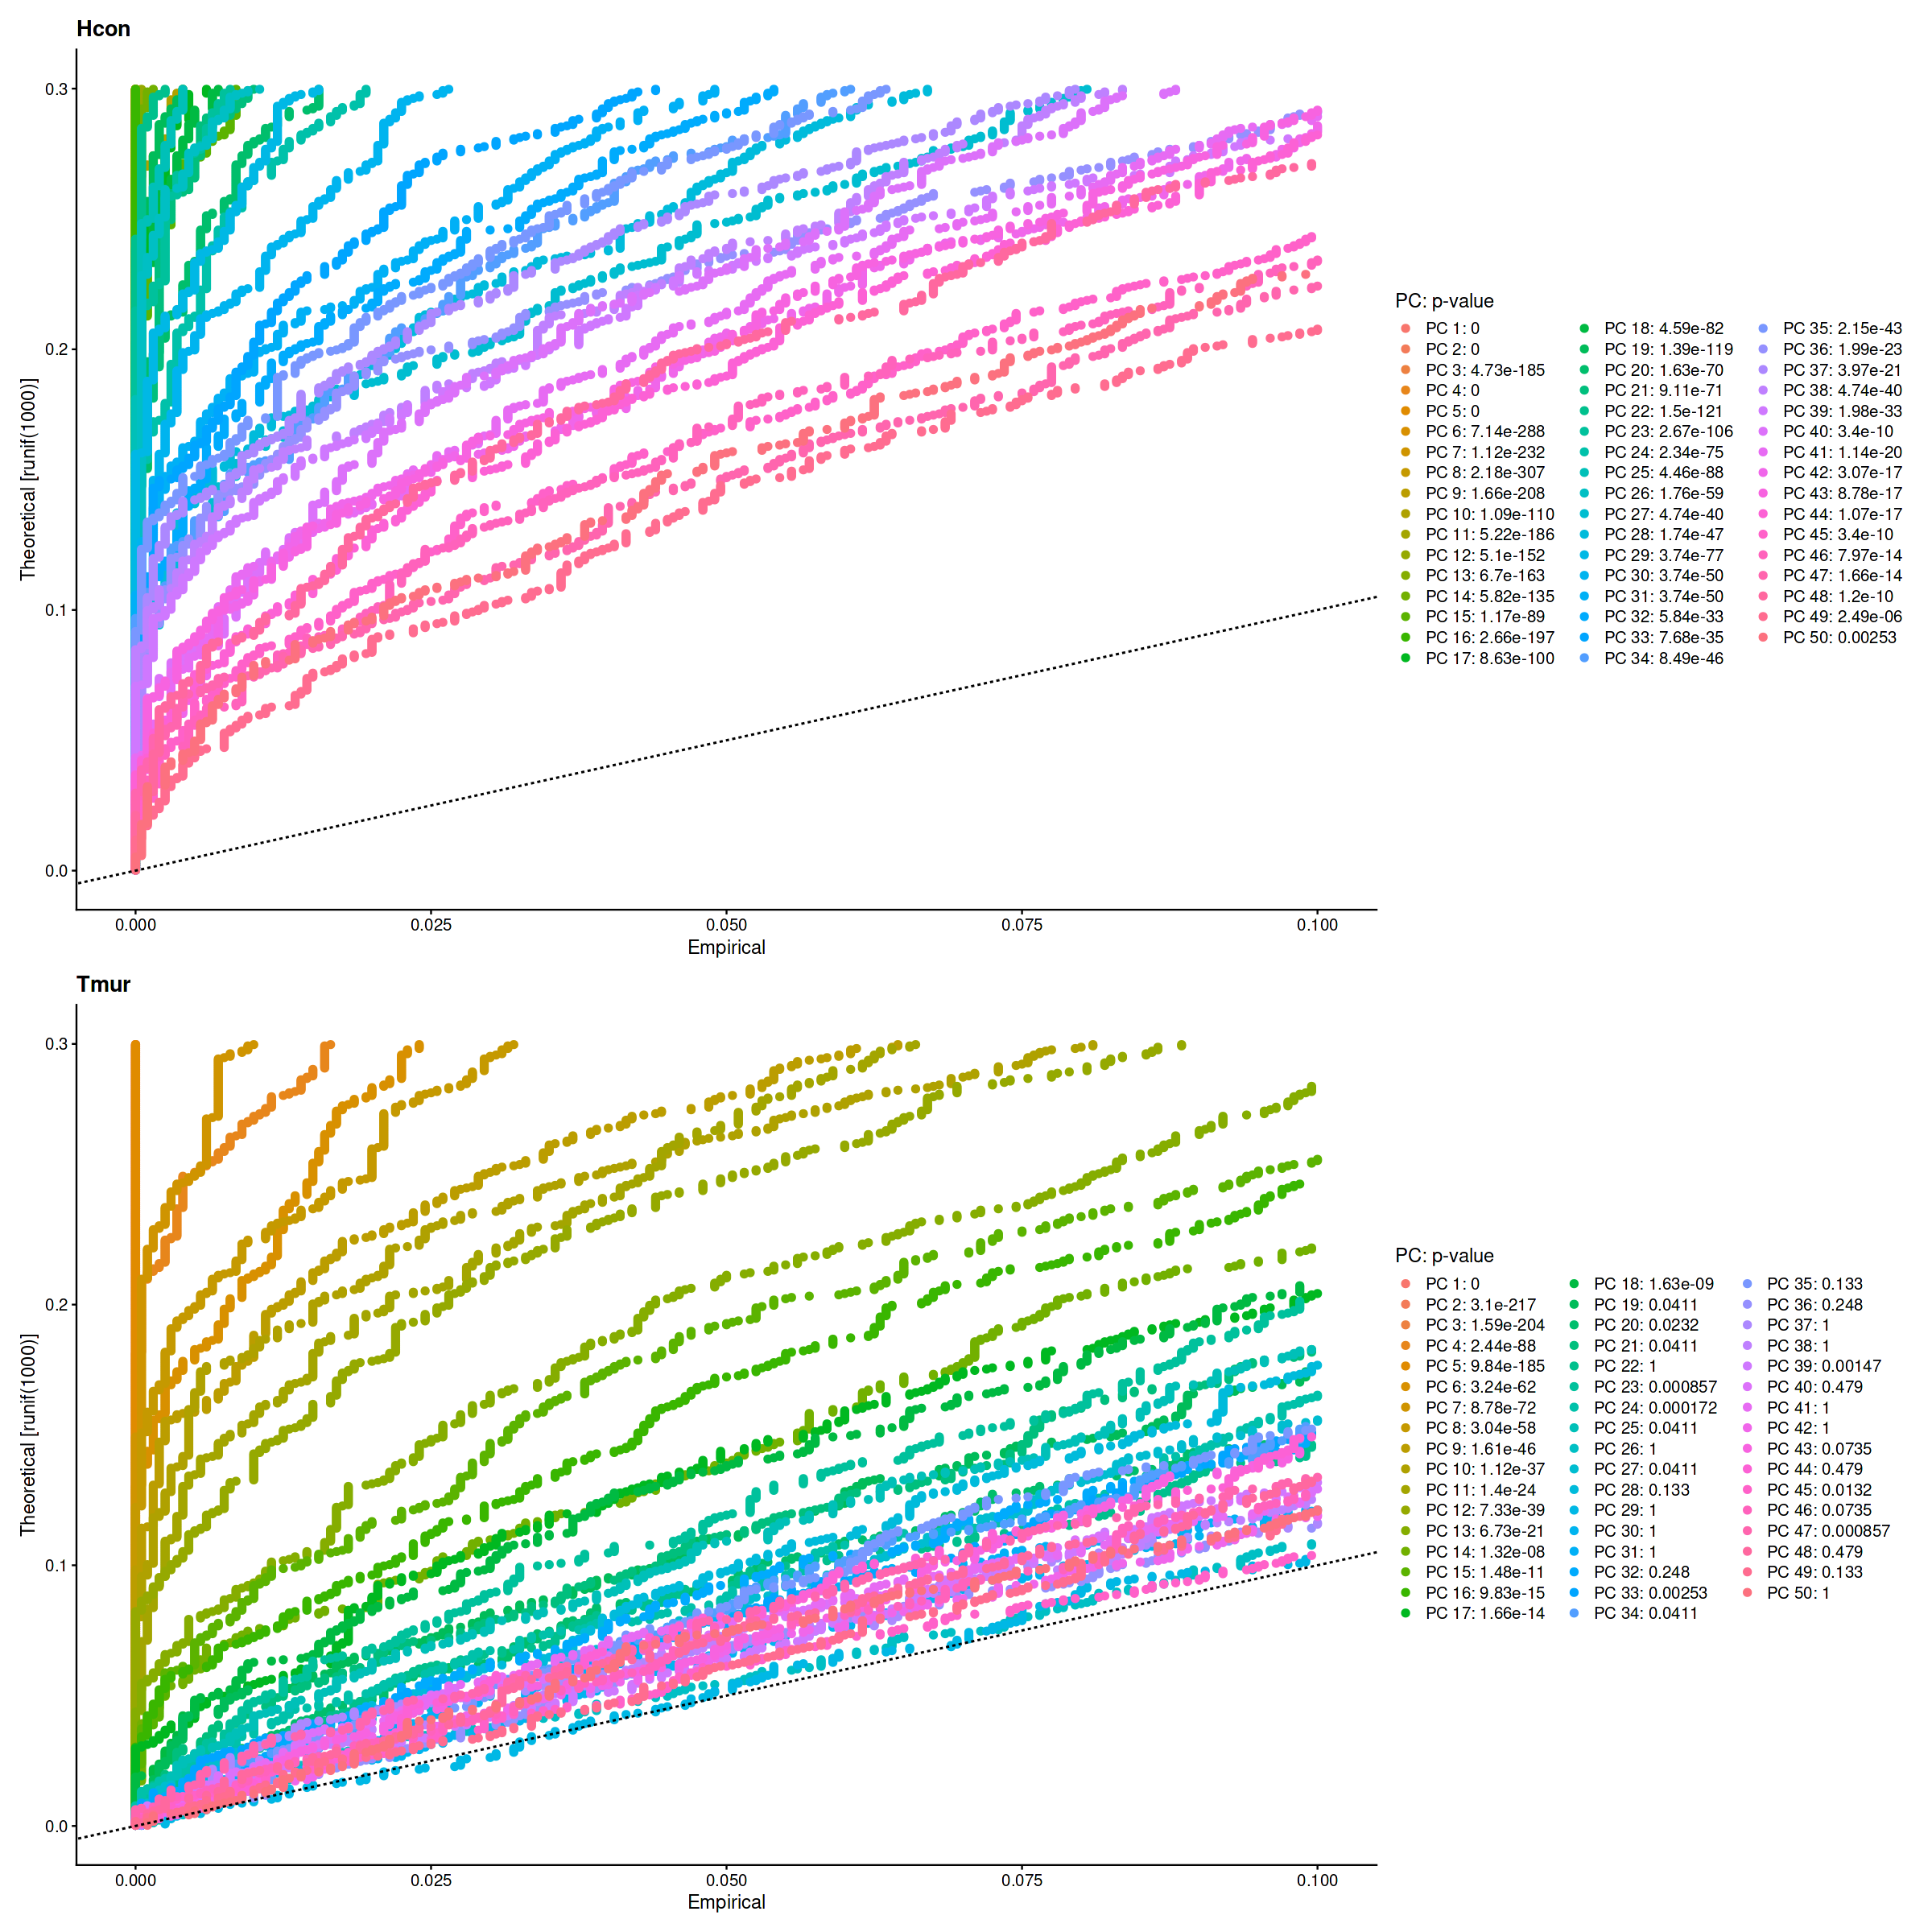

In [18]:
options(repr.plot.width=20, repr.plot.height=20)

p1 <- JackStrawPlot(hcon_js, dims = 1:50) + ggtitle("Hcon")
p2 <- JackStrawPlot(tmur_js, dims = 1:50) + ggtitle("Tmur")

p1 + p2 + plot_layout(nrow = 2)

ggsave("jackstraw_plots.png", width = 15, height = 15, dpi = 600, units = "in")

In [182]:
sessionInfo()

R version 4.4.0 (2024-04-24)
Platform: x86_64-pc-linux-gnu
Running under: Ubuntu 22.04.5 LTS

Matrix products: default
BLAS:   /software/isg/languages/R/4.4.0/exec/lib/R/lib/libRblas.so 
LAPACK: /software/isg/languages/R/4.4.0/exec/lib/R/lib/libRlapack.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_GB.utf8       LC_NUMERIC=C             
 [3] LC_TIME=en_GB.utf8        LC_COLLATE=en_GB.utf8    
 [5] LC_MONETARY=en_GB.utf8    LC_MESSAGES=en_GB.utf8   
 [7] LC_PAPER=en_GB.utf8       LC_NAME=C                
 [9] LC_ADDRESS=C              LC_TELEPHONE=C           
[11] LC_MEASUREMENT=en_GB.utf8 LC_IDENTIFICATION=C      

time zone: Europe/London
tzcode source: system (glibc)

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] patchwork_1.3.2             dittoSeq_1.18.0            
 [3] sctransform_0.4.2           plotly_4.12.0              
 [5] scDblFinder_1.20.2          scales_1.4.0       

In [19]:
# Remove all hidden and visible objects stored in R workspace
rm(list = ls(all.names = TRUE))
quit(save = "no")